# 飞行穿越：规划轨迹与 EKF 实际轨迹

从 ROS 1 bag 中读取 `/flygripper/trajectory` 的分段多项式和 `/ekf/ekf_odom`，生成 3D、XY 与 XZ 动画。规划按发布时间出现；橙色轨迹为 EKF 估计位置。

**使用方式：**从 HIARM 仓库或其子目录启动 Notebook，运行全部单元格。修改下方参数可分析其他 bag。内核需要 `rosbags`、`numpy`、`matplotlib`、`Pillow`、`PyYAML` 和 `IPython`，不需要 ROS。

首次安装可在 Notebook 内使用 `%pip install rosbags numpy matplotlib pillow pyyaml`。

In [1]:
from types import SimpleNamespace
import json
import math
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
import numpy as np
from rosbags.highlevel import AnyReader
import yaml

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/flygripper_planner/params/real_crossing.yaml').is_file()), None)
if ROOT is None:
    raise RuntimeError('请从 HIARM 仓库目录或其子目录启动 Notebook')
DEFAULT_CONFIG = ROOT / 'src/flygripper_planner/params/real_crossing.yaml'


from IPython.display import display, Image, Markdown


## 参数

`START`、`END` 是相对于 bag 录制开始时间的秒数；设为 `None` 时自动覆盖首段规划前 1 秒至末段规划结束后 1 秒。输出默认位于工作区 chat 目录下的新目录。`CONFIG` 显示的是当前 YAML，不能证明录制时参数相同；设 `SHOW_GOALS = False` 可隐藏。

In [2]:
BAG = Path('/Users/lzf/Documents/wfzf/2026-11-03-11-34-58.bag')
CONFIG = ROOT / 'src/flygripper_planner/params/real_crossing.yaml'
OUTPUT_DIR = None  # 例如 Path('/tmp/crossing_output')
START = None
END = None
FPS = 8
SPEED = 2.0  # 2 表示 2 倍速
SHOW_GOALS = True
ODOM_TOPIC = '/ekf/ekf_odom'
PLAN_TOPIC = '/flygripper/trajectory'
STATUS_TOPIC = '/flygripper/flight_trajectory_status'
PLAN_STEP = 0.025


## 数据读取与轨迹重建

多项式系数按项目中 Eigen 的列优先顺序解码；飞控状态按轨迹 ID 和起始时间联合匹配。EKF 中断超过 150 ms 时会断开轨迹，避免用直线虚构缺失位置。

In [3]:
def ns(stamp):
    return int(stamp.sec) * 1_000_000_000 + int(stamp.nanosec)


def sample_plan(message, step):
    """Eigen serializes each coefficient matrix column-major, highest power first."""
    times, points = [], []
    offset = 0.0
    if not message.xyz_pieces:
        raise ValueError('Trajectory has no XYZ pieces')
    for piece in message.xyz_pieces:
        duration = float(piece.duration)
        coeff = np.asarray(piece.coeff, dtype=float)
        if (piece.dim != 3 or piece.order not in (5, 7) or not math.isfinite(duration)
                or duration <= 0 or coeff.size != 3 * (piece.order + 1)
                or not np.isfinite(coeff).all()):
            raise ValueError('Invalid polynomial piece')
        matrix = coeff.reshape((3, piece.order + 1), order='F')
        local = np.linspace(0, duration, max(2, math.ceil(duration / step) + 1))
        if times:
            local = local[1:]
        result = np.array([np.polyval(row, local) for row in matrix]).T
        times.extend(offset + local)
        points.extend(result)
        offset += duration
    return np.asarray(times), np.asarray(points), offset


def read_data(path, odom_topic, plan_topic, status_topic, step):
    odom, plans, status, frames = [], [], [], set()
    with AnyReader([path]) as reader:
        bag_start_ns = reader.start_time
        available = {c.topic for c in reader.connections}
        missing = {odom_topic, plan_topic} - available
        if missing:
            raise ValueError('Missing required topics: ' + ', '.join(sorted(missing)))
        topics = {odom_topic, plan_topic, status_topic}
        for conn, record_ns, raw in reader.messages(connections=[c for c in reader.connections if c.topic in topics]):
            msg = reader.deserialize(raw, conn.msgtype)
            if conn.topic == odom_topic:
                p = msg.pose.pose.position
                stamp = ns(msg.header.stamp)
                if stamp > 0 and all(math.isfinite(v) for v in (p.x, p.y, p.z)):
                    odom.append((stamp, p.x, p.y, p.z))
                    frames.add(msg.header.frame_id or '(empty)')
            elif conn.topic == plan_topic:
                elapsed, xyz, duration = sample_plan(msg, step)
                stamp = ns(msg.header.stamp)
                if not stamp:
                    raise ValueError('Trajectory has zero header stamp')
                plans.append(dict(start_ns=stamp, record_ns=record_ns, id=int(msg.id),
                                  t=elapsed, xyz=xyz, duration=duration))
            else:
                stamp = ns(msg.header.stamp)
                if stamp:
                    status.append((stamp, bool(msg.trajectory_active), int(msg.trajectory_id),
                                   ns(msg.trajectory_start)))
    if len(odom) < 2 or not plans:
        raise ValueError('Need at least two finite EKF samples and one planned trajectory')
    if len(frames) != 1:
        raise ValueError('EKF coordinate frame changes within bag: ' + ', '.join(sorted(frames)))
    odom.sort(key=lambda row: row[0])
    status.sort(key=lambda row: row[0])
    plans.sort(key=lambda p: p['record_ns'])
    return bag_start_ns, odom, plans, status, next(iter(frames))


def load_goals(path):
    if path is None:
        return []
    with path.open() as f:
        cfg = yaml.safe_load(f)
    goals = []
    for i in range(int(cfg.get('task_num', 0))):
        task = cfg.get(f'task_{i}', {})
        for j in range(int(task.get('plan_point_num', 0))):
            p = task.get(f'plan_point_{j}')
            if p and all(k in p for k in ('x', 'y', 'z')):
                goals.append((f'{i}.{j}', [float(p[k]) for k in ('x', 'y', 'z')]))
    return goals


def match_status(time_ns, status, max_age_ns=150_000_000):
    if not status:
        return None
    idx = np.searchsorted(status[0], time_ns, side='right') - 1
    if idx < 0 or time_ns - status[0][idx] > max_age_ns:
        return None
    return status[1][idx]



## 生成动画

虚线为已发布的规划，彩色区分不同规划；橙色实线为 EKF 位置。视图为便于观察而独立缩放坐标轴，轴上数值仍以米为单位。标题中的 active 仅表示飞控本地轨迹采样和命令发布状态。

In [4]:
def analyze_crossing(args):
    if not all(math.isfinite(x) and x > 0 for x in (args.fps, args.speed, args.plan_step)):
        raise ValueError('--fps, --speed and --plan-step must be finite and positive')
    bag = args.bag.expanduser().resolve()
    bag_start, rows, plans, status_rows, frame = read_data(bag, args.odom_topic, args.plan_topic, args.status_topic, args.plan_step)
    goal_path = None if args.no_goals else args.config.expanduser().resolve()
    goals = load_goals(goal_path)
    odom_ns = np.array([r[0] for r in rows], dtype=np.int64)
    xyz = np.array([r[1:] for r in rows])
    status = (np.array([r[0] for r in status_rows], dtype=np.int64), status_rows) if status_rows else None
    begin = (bag_start + int(args.start * 1e9) if args.start is not None else
             max(int(odom_ns[0]), plans[0]['record_ns'] - 1_000_000_000))
    finish = (bag_start + int(args.end * 1e9) if args.end is not None else
              min(int(odom_ns[-1]), max(p['start_ns'] + int(p['duration'] * 1e9) for p in plans) + 1_000_000_000))
    if not (int(odom_ns[0]) <= begin < finish <= int(odom_ns[-1])):
        raise ValueError('Animation window must lie inside the EKF header-time range')
    mask = (odom_ns >= begin) & (odom_ns <= finish)
    if mask.sum() < 2:
        raise ValueError('Animation window has fewer than two EKF samples')
    window_xyz = xyz[mask]
    relevant = [p for p in plans if p['record_ns'] <= finish and p['start_ns'] + int(p['duration'] * 1e9) >= begin]
    if not relevant:
        raise ValueError('No planned trajectories overlap the animation window')
    all_points = np.vstack([window_xyz] + [p['xyz'] for p in relevant] + ([np.array([g[1] for g in goals])] if goals else []))
    lows, highs = all_points.min(axis=0), all_points.max(axis=0)
    margin = np.maximum((highs - lows) * 0.1, 0.15)
    lows -= margin; highs += margin
    output = (args.output_dir or ROOT.parent / 'chat' / (bag.stem + '_crossing_analysis')).expanduser().resolve()
    output.mkdir(parents=True, exist_ok=True)
    duration = (finish - begin) * 1e-9
    frame_count = max(2, math.ceil(duration * args.fps / args.speed) + 1)
    ticks = np.linspace(begin, finish, frame_count).astype(np.int64)
    colors = plt.get_cmap('tab10')
    summary = {'bag': str(bag), 'bag_start_unix': bag_start * 1e-9,
               'window_seconds_from_bag_start': [(begin-bag_start)*1e-9, (finish-bag_start)*1e-9],
               'ekf_topic': args.odom_topic, 'ekf_frame': frame, 'plan_topic': args.plan_topic,
               'status_topic': args.status_topic, 'status_available': bool(status_rows),
               'config_current_not_recorded_proof': str(goal_path) if goal_path else None,
               'animation_fps': args.fps, 'playback_speed': args.speed, 'frame_count': frame_count,
               'plans': []}
    for i, plan in enumerate(relevant):
        matched = [s for s in status_rows if s[1] and s[2] == plan['id'] and s[3] == plan['start_ns']]
        summary['plans'].append({'index': i, 'id': plan['id'], 'start_seconds_from_bag_start': (plan['start_ns']-bag_start)*1e-9,
                                 'publication_seconds_from_bag_start': (plan['record_ns']-bag_start)*1e-9,
                                 'duration_seconds': plan['duration'], 'start_xyz': plan['xyz'][0].tolist(),
                                 'end_xyz': plan['xyz'][-1].tolist(), 'active_status_samples': len(matched)})
    for mode in ('2d', '3d'):
        if mode == '2d':
            fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
            fig.subplots_adjust(left=.07, right=.98, bottom=.18, top=.87, wspace=.2)
            dims = [(0, 1), (0, 2)]
        else:
            fig = plt.figure(figsize=(10, 7), layout='constrained')
            axes = [fig.add_subplot(111, projection='3d')]
            dims = [(0, 1, 2)]
        for ax, dim in zip(axes, dims):
            ax.set_xlabel('X (m)'); ax.set_ylabel(('Y' if dim[1] == 1 else 'Z') + ' (m)')
            ax.set_xlim(lows[0], highs[0]); ax.set_ylim(lows[dim[1]], highs[dim[1]])
            ax.grid(alpha=.25)
            if mode == '3d':
                ax.set_zlabel('Z (m)'); ax.set_zlim(lows[2], highs[2])
                # Keep the long, narrow crossing legible; label the distortion.
                spans = highs - lows
                ax.set_box_aspect([spans[0], max(spans[1], spans[0] * .35),
                                   max(spans[2], spans[0] * .35)])
                ax.view_init(elev=23, azim=-62)
                ax.set_title('3D view (Y/Z visually enlarged)')
            else:
                ax.set_aspect('auto'); ax.set_title(('XY top view' if dim[1] == 1 else 'XZ side view') + ' (axes scaled independently)')
            for name, pos in goals:
                ax.scatter(*[pos[k] for k in dim], marker='x', color='#323232', s=45)
                ax.text(*[pos[k] for k in dim], f' {name}', fontsize=8)
        artists = []
        for ax, dim in zip(axes, dims):
            plan_lines = [ax.plot(*([[]] * len(dim)), ls='--', lw=2, color=colors(i % 10), alpha=.95, zorder=5)[0] for i in range(len(relevant))]
            trail = ax.plot(*([[]] * len(dim)), color='#dc552f', lw=1.5, zorder=3)[0]
            dot = ax.plot(*([[]] * len(dim)), marker='o', color='#dc552f', markersize=6)[0]
            artists.append((dim, plan_lines, trail, dot))
        legend = [Line2D([0],[0], color='#dc552f', lw=2, label='EKF actual path'),
                  Line2D([0],[0], color='#536ab5', ls='--', lw=2, label='Published plans (colored by order)')]
        if goals:
            legend.append(Line2D([0],[0], marker='x', color='#333333', ls='', label='Current YAML goals (task.point)'))
        fig.legend(handles=legend, loc='lower center', ncol=3 if goals else 2, fontsize=9)
        title = fig.suptitle('')
        def set_line(line, pts, dim):
            line.set_data(pts[:, dim[0]], pts[:, dim[1]])
            if len(dim) == 3:
                line.set_3d_properties(pts[:, dim[2]])
        def update(t):
            past = (odom_ns >= begin) & (odom_ns <= t)
            path = xyz[past].copy()
            # A NaN breaks the trail at missing EKF samples rather than inventing motion.
            stamps = odom_ns[past]
            if len(path) > 1:
                path[1:][np.diff(stamps) > 150_000_000] = np.nan
            last_age = int(t - stamps[-1]) if len(stamps) else 10**18
            point = xyz[np.searchsorted(odom_ns, t, side='right')-1:np.searchsorted(odom_ns, t, side='right')] if last_age <= 150_000_000 else np.empty((0,3))
            for dim, lines, trail, dot in artists:
                for line, plan in zip(lines, relevant):
                    set_line(line, plan['xyz'] if plan['record_ns'] <= t else np.empty((0,3)), dim)
                set_line(trail, path, dim); set_line(dot, point, dim)
            state = match_status(t, status)
            label = 'status unavailable/stale' if state is None else 'no active trajectory'
            if state and state[1]:
                matches = [str(i) for i,p in enumerate(relevant) if p['id'] == state[2] and p['start_ns'] == state[3]]
                label = 'local trajectory active: plan ' + (matches[0] if matches else 'unmatched')
            title.set_text(f'Crossing | bag +{(t-bag_start)*1e-9:.1f} s | {label} | {args.speed:g}x')
            return []
        animation = FuncAnimation(fig, update, frames=ticks, blit=False, repeat=True)
        dest = output / f'crossing_{mode}.gif'
        print(f'Rendering {dest} ({frame_count} frames)', flush=True)
        animation.save(dest, writer=PillowWriter(fps=args.fps), dpi=100)
        update(finish)
        fig.savefig(output / f'crossing_{mode}.png', dpi=140)
        plt.close(fig)
    (output / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2) + '\n')
    print(json.dumps(summary, ensure_ascii=False, indent=2))


In [5]:
args = SimpleNamespace(
    bag=BAG, config=CONFIG, output_dir=OUTPUT_DIR, start=START, end=END,
    fps=FPS, speed=SPEED, no_goals=not SHOW_GOALS, odom_topic=ODOM_TOPIC,
    plan_topic=PLAN_TOPIC, status_topic=STATUS_TOPIC, plan_step=PLAN_STEP,
)
analyze_crossing(args)
output_dir = (OUTPUT_DIR or ROOT.parent / 'chat' / (BAG.stem + '_crossing_analysis')).expanduser().resolve()


Rendering /Users/lzf/Documents/wfzf/2026-11-03-11-34-58_crossing_analysis/crossing_2d.gif (79 frames)
Rendering /Users/lzf/Documents/wfzf/2026-11-03-11-34-58_crossing_analysis/crossing_3d.gif (79 frames)
{
  "bag": "/Users/lzf/Documents/wfzf/2026-11-03-11-34-58.bag",
  "bag_start_unix": 1793676903.8572602,
  "window_seconds_from_bag_start": [
    22.371864265000003,
    41.770545147
  ],
  "ekf_topic": "/ekf/ekf_odom",
  "ekf_frame": "world",
  "plan_topic": "/flygripper/trajectory",
  "status_topic": "/flygripper/flight_trajectory_status",
  "status_available": true,
  "config_current_not_recorded_proof": "/Users/lzf/Documents/wfzf/HIARM/src/flygripper_planner/params/real_crossing.yaml",
  "animation_fps": 8,
  "playback_speed": 2.0,
  "frame_count": 79,
  "plans": [
    {
      "index": 0,
      "id": 0,
      "start_seconds_from_bag_start": 23.363596445000002,
      "publication_seconds_from_bag_start": 23.371864265000003,
      "duration_seconds": 4.0554783593679575,
      "start_x

## 3D 动画

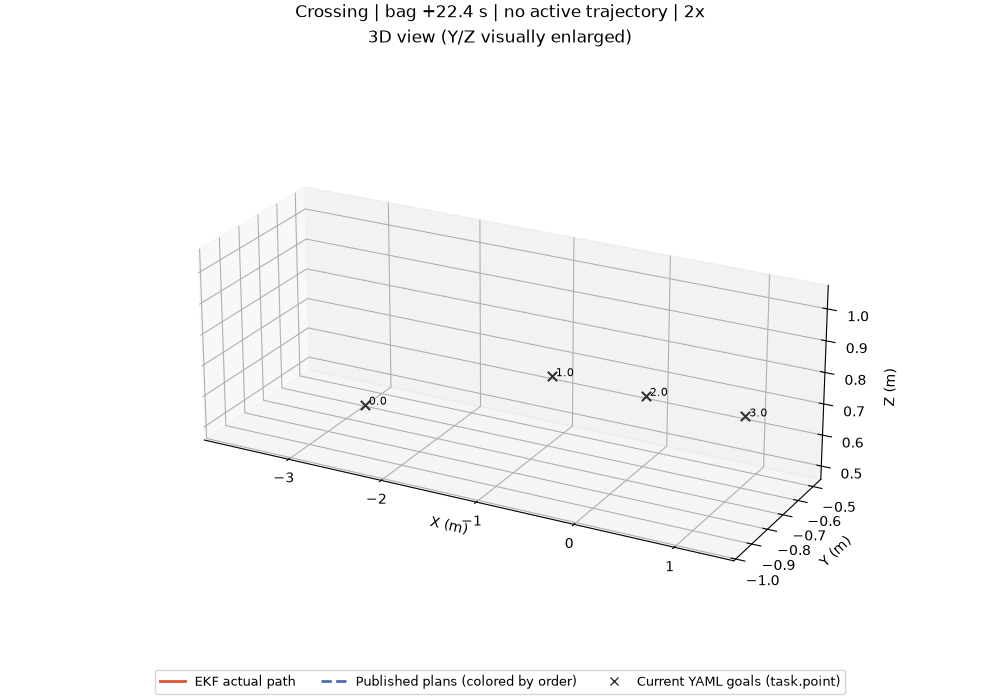

In [6]:
display(Image(filename=str(output_dir / 'crossing_3d.gif')))


## 2D 动画：XY 俯视与 XZ 侧视

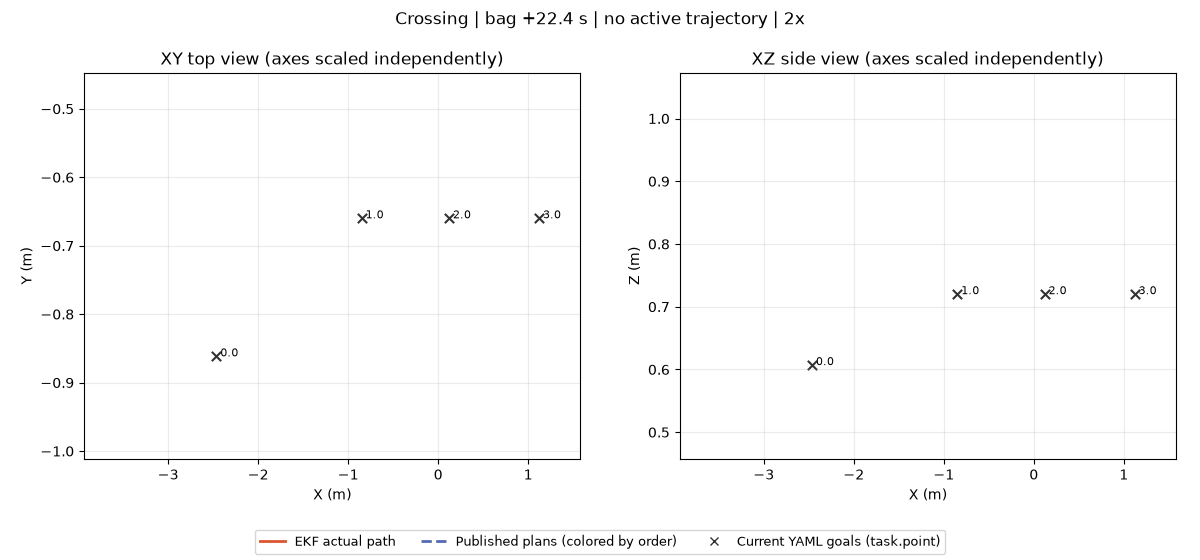

In [7]:
display(Image(filename=str(output_dir / 'crossing_2d.gif')))


## 轨迹摘要与解释边界

下表的时间相对 bag 开始。飞控状态样本按 ID 和轨迹起始时间匹配；ID 可能被不同轨迹复用。状态为 active 不能单独证明 FCU 收到命令，EKF 位置也不能证明夹爪动作或穿越时没有碰撞。

In [8]:
summary = json.loads((output_dir / 'summary.json').read_text())
print('EKF frame:', summary['ekf_frame'])
print('动画窗口（bag 秒）:', summary['window_seconds_from_bag_start'])
print('序号  ID   规划起始  发布  持续时间  本地 active 状态样本数  终点 XYZ (m)')
for p in summary['plans']:
    print(f"{p['index']:>3} {p['id']:>3}  {p['start_seconds_from_bag_start']:>8.3f}  "
          f"{p['publication_seconds_from_bag_start']:>6.3f}  {p['duration_seconds']:>7.3f}  "
          f"{p['active_status_samples']:>6}  {tuple(round(v, 3) for v in p['end_xyz'])}")
print('输出目录:', output_dir)


EKF frame: world
动画窗口（bag 秒）: [22.371864265000003, 41.770545147]
序号  ID   规划起始  发布  持续时间  本地 active 状态样本数  终点 XYZ (m)
  0   0    23.364  23.372    4.055      67  (-2.465, -0.862, 0.607)
  1   0    26.799  26.822    6.261     123  (-0.85, -0.66, 0.72)
  2   0    33.112  33.120    3.652      71  (0.12, -0.66, 0.72)
  3   0    37.017  37.044    3.753      68  (1.12, -0.66, 0.72)
输出目录: /Users/lzf/Documents/wfzf/2026-11-03-11-34-58_crossing_analysis
